# Import

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Data

In [2]:
sns.set_theme(style="whitegrid")

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(
    PROJECT_ROOT / "data" / "raw" / "heart_disease_raw.csv"
)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
display(df.head())

df.info()

display(df.describe().T)
display(df.dtypes.rename("data_type").to_frame())

Rows: 303
Columns: 14


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


,data_type
age,int64
sex,int64
cp,int64
trestbps,int64
chol,int64
fbs,int64
restecg,int64
thalach,int64
exang,int64
oldpeak,float64


# Check missing values & Remove Duplicate values

In [3]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": df.isna().mean() * 100
})

display(
    missing_summary
    .sort_values("missing_count", ascending=False)
)
print("Question marks per column:")
display((df.astype(str) == "?").sum())
df = df.replace("?", np.nan)

# Convert columns to numeric where appropriate.
# Invalid values, if any, become NaN and can be investigated.
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Missing values after normalization:")
display(df.isna().sum())

print("Duplicate rows:", df.duplicated().sum())


,missing_count,missing_percentage
ca,4,1.320132
thal,2,0.660066
age,0,0.000000
sex,0,0.000000
cp,0,0.000000
trestbps,0,0.000000
chol,0,0.000000
fbs,0,0.000000
restecg,0,0.000000
thalach,0,0.000000


Question marks per column:


age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64

Missing values after normalization:


age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

Duplicate rows: 0


# Class Balance

num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

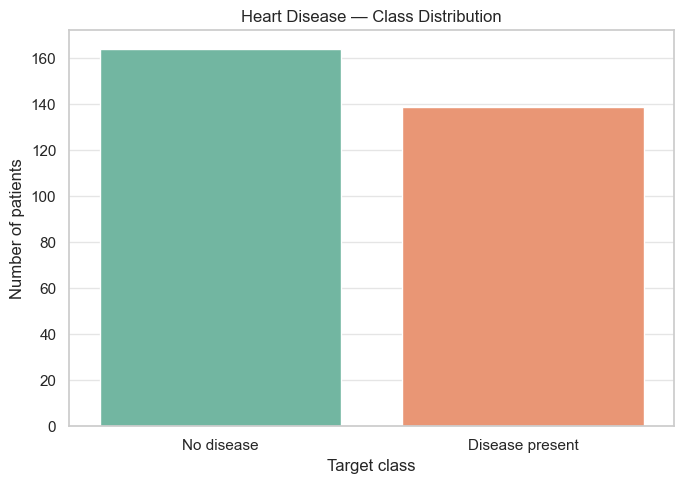

In [4]:
target_counts = df["num"].value_counts(dropna=False).sort_index()
display(target_counts)

binary_target = (df["num"] > 0).astype(int)

plt.figure(figsize=(7, 5))
ax = sns.countplot(
    x=binary_target,
    hue=binary_target,
    palette="Set2",
    legend=False
)
ax.set_xticks([0, 1], ["No disease", "Disease present"])
ax.set_title("Heart Disease — Class Distribution")
ax.set_xlabel("Target class")
ax.set_ylabel("Number of patients")

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "class_balance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Histogram Of Numerical Features

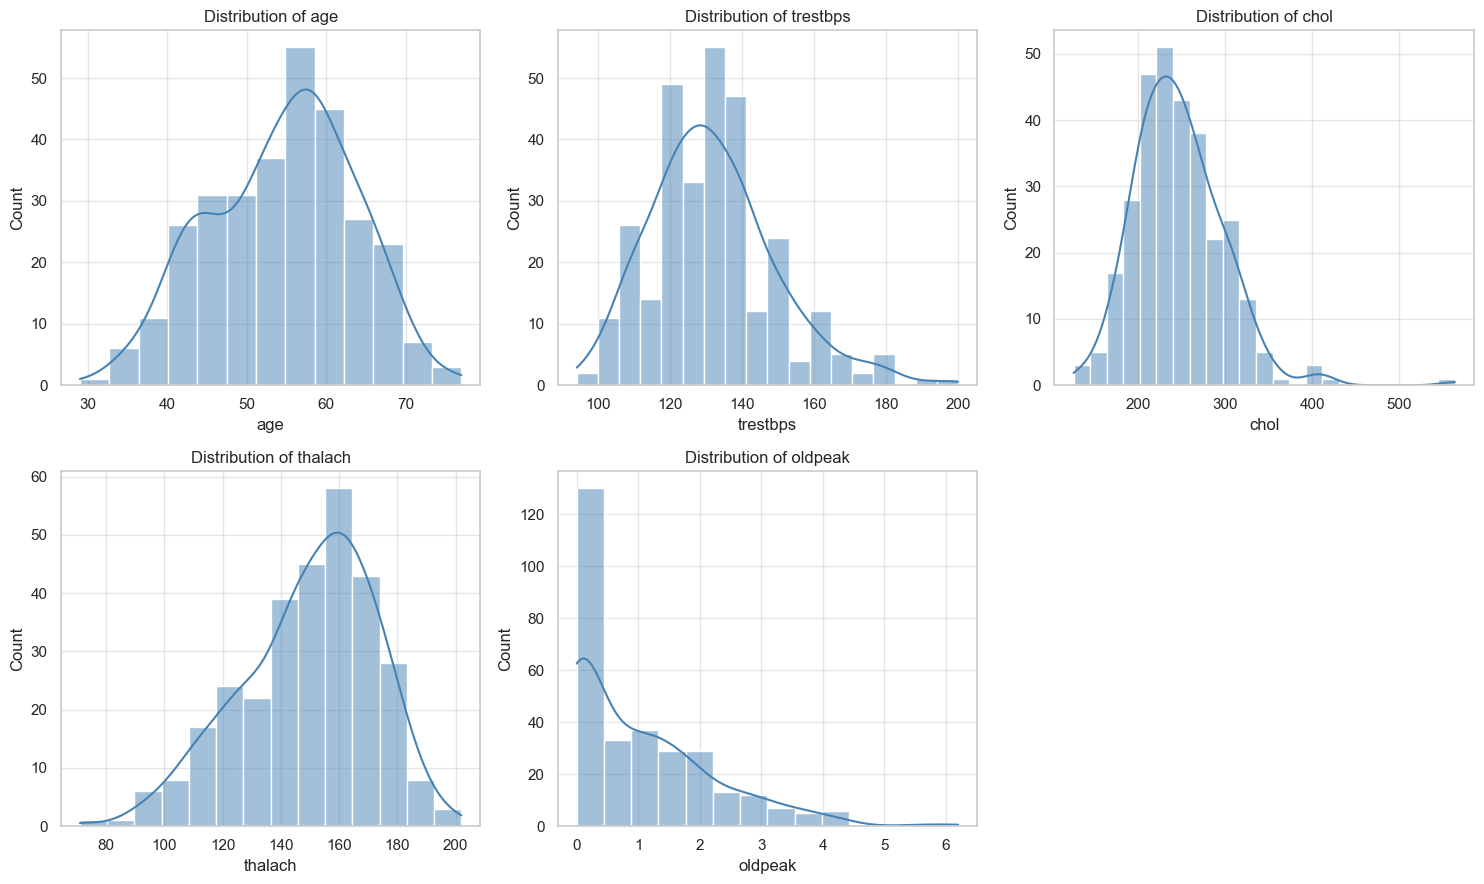

In [5]:
numeric_features = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, col in enumerate(numeric_features):
    sns.histplot(
        data=df,
        x=col,
        kde=True,
        ax=axes[i],
        color="steelblue"
    )
    axes[i].set_title(f"Distribution of {col}")

axes[-1].set_visible(False)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "numeric_histograms.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Correlation heatmap

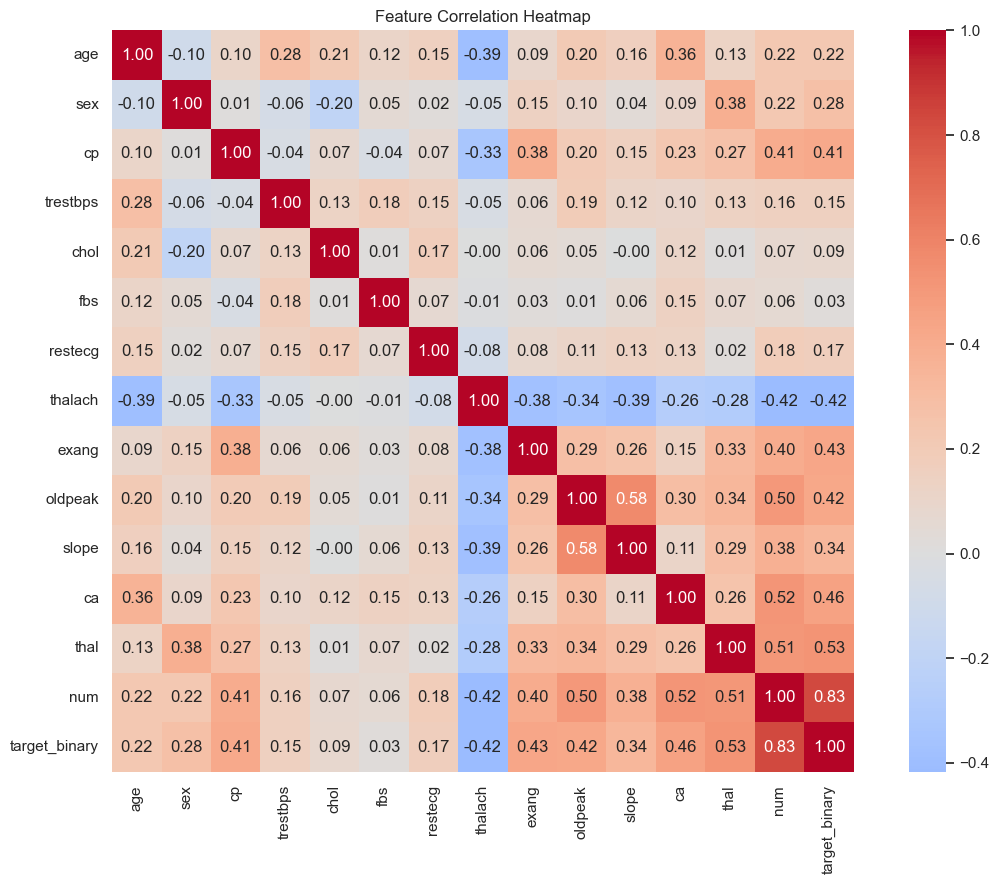

In [6]:
corr_df = df.copy()
corr_df["target_binary"] = (corr_df["num"] > 0).astype(int)

correlation_matrix = corr_df.select_dtypes(
    include=np.number
).corr()

plt.figure(figsize=(12, 9))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Cleanup Data & Save the data

In [7]:
# Start from the raw data again so cleaning is reproducible
clean_df = pd.read_csv(
    PROJECT_ROOT / "data" / "raw" / "heart_disease_raw.csv"
)

clean_df = clean_df.replace("?", np.nan)

for col in clean_df.columns:
    clean_df[col] = pd.to_numeric(clean_df[col], errors="coerce")

# Remove exact duplicate rows
duplicates_removed = int(clean_df.duplicated().sum())
clean_df = clean_df.drop_duplicates().copy()

# Target must be present to use a record for supervised learning
missing_target = int(clean_df["num"].isna().sum())
clean_df = clean_df.dropna(subset=["num"]).copy()

# Convert the original multiclass target into a binary target
clean_df["target"] = (clean_df["num"] > 0).astype(int)

# Identify categorical columns and continuous numerical columns
categorical_features = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

numeric_features = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

# Fill missing feature values using training-independent,
# simple descriptive statistics for this initial cleaned dataset.
for col in numeric_features:
    clean_df[col] = clean_df[col].fillna(clean_df[col].median())

for col in categorical_features:
    clean_df[col] = clean_df[col].fillna(
        clean_df[col].mode().iloc[0]
    )

# Keep the binary target and input features.
# Drop the original target to avoid accidentally using it as a feature.
feature_columns = numeric_features + categorical_features
final_df = clean_df[feature_columns + ["target"]].copy()

print("Duplicate rows removed:", duplicates_removed)
print("Rows removed due to missing target:", missing_target)
print("Final dataset shape:", final_df.shape)
print("Missing values remaining:", final_df.isna().sum().sum())

display(final_df.head())

processed_path = (
    PROJECT_ROOT / "data" / "processed" / "heart_disease_clean.csv"
)

final_df.to_csv(processed_path, index=False)

print("Cleaned dataset saved to:", processed_path)

Duplicate rows removed: 0
Rows removed due to missing target: 0
Final dataset shape: (303, 14)
Missing values remaining: 0


,age,trestbps,chol,thalach,oldpeak,sex,cp,fbs,restecg,exang,slope,ca,thal,target
0,63,145,233,150,2.3,1,1,1,2,0,3,0.0,6.0,0
1,67,160,286,108,1.5,1,4,0,2,1,2,3.0,3.0,1
2,67,120,229,129,2.6,1,4,0,2,1,2,2.0,7.0,1
3,37,130,250,187,3.5,1,3,0,0,0,3,0.0,3.0,0
4,41,130,204,172,1.4,0,2,0,2,0,1,0.0,3.0,0


Cleaned dataset saved to: D:\MTech\SEM3\MLOps\Assignment1\heart-disease-mlops\data\processed\heart_disease_clean.csv


# Validate the final data

In [8]:
assert final_df.isna().sum().sum() == 0
assert set(final_df["target"].unique()).issubset({0, 1})
assert "num" not in final_df.columns

print("All validation checks passed.")
print("\nTarget distribution:")
display(final_df["target"].value_counts().sort_index())

print("\nTarget percentages:")
display(
    (final_df["target"].value_counts(normalize=True) * 100)
    .round(2)
)

All validation checks passed.

Target distribution:


target
0    164
1    139
Name: count, dtype: int64


Target percentages:


target
0    54.13
1    45.87
Name: proportion, dtype: float64

# Generate a summary report

In [9]:
summary = {
    "raw_rows": len(df),
    "raw_columns": len(df.columns),
    "clean_rows": len(final_df),
    "clean_columns": len(final_df.columns),
    "duplicates_removed": duplicates_removed,
    "missing_target_rows_removed": missing_target,
    "remaining_missing_values": int(final_df.isna().sum().sum()),
    "no_disease_count": int((final_df["target"] == 0).sum()),
    "disease_present_count": int((final_df["target"] == 1).sum()),
}

summary_df = pd.DataFrame(
    summary.items(),
    columns=["Metric", "Value"]
)

display(summary_df)

summary_df.to_csv(
    PROJECT_ROOT / "reports" / "eda_data_summary.csv",
    index=False
)

,Metric,Value
0,raw_rows,303
1,raw_columns,14
2,clean_rows,303
3,clean_columns,14
4,duplicates_removed,0
5,missing_target_rows_removed,0
6,remaining_missing_values,0
7,no_disease_count,164
8,disease_present_count,139
